In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import xarray as xr
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import calendar
sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_demand_website_data = Path(
    Path(paths["path_data_processed"]) / "website_data" / "demand"
)

path_temperature_website_data = (
    Path(paths["path_data_processed"]) / "website_data" / "temperature"
)

In [4]:
canton_path = (
    Path(paths["path_data_processed"])
    / "maps"
    / "cantons_ch"
    / "swissBOUNDARIES3D_1_5_TLM_KANTONSGEBIET.shp"
)

# Analysis

## Heating and cooling days

### Heating and cooling days from per-grid cell population-weighted cooling and heating days

In [29]:
import re

ds_demand = []
for path in path_demand_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp[0-9][0-9].nc"):
    scenario_match = re.search(r"rcp\d{2}", path.stem)
    scenario = scenario_match.group(0)
    ds_demand.append(xr.open_dataset(path).expand_dims({"scenario": [scenario]}))

# combine list of datasets into one dataset along the 'scenario' dimension
ds_demand = xr.concat(ds_demand, dim="scenario")

In [30]:
list_ds_demand = []
centers = [2030, 2040, 2050]
for center in centers:
    start = center - 9
    end = center + 10
    ds_center_mean = (
        ds_demand.sel(time=slice(str(start), str(end)))
        .groupby("time.month")
        .mean("time")
    )
    months = ds_center_mean["month"].values
    month_ends = (
        pd.to_datetime([f"{center}-{int(m):02d}-01" for m in months])
        .to_period("M")
        .to_timestamp("M")
    )
    ds_center_mean = ds_center_mean.assign_coords(month=month_ends)
    list_ds_demand.append(ds_center_mean)
ds_demand_centers = xr.concat(list_ds_demand, dim="month")

#### Heating

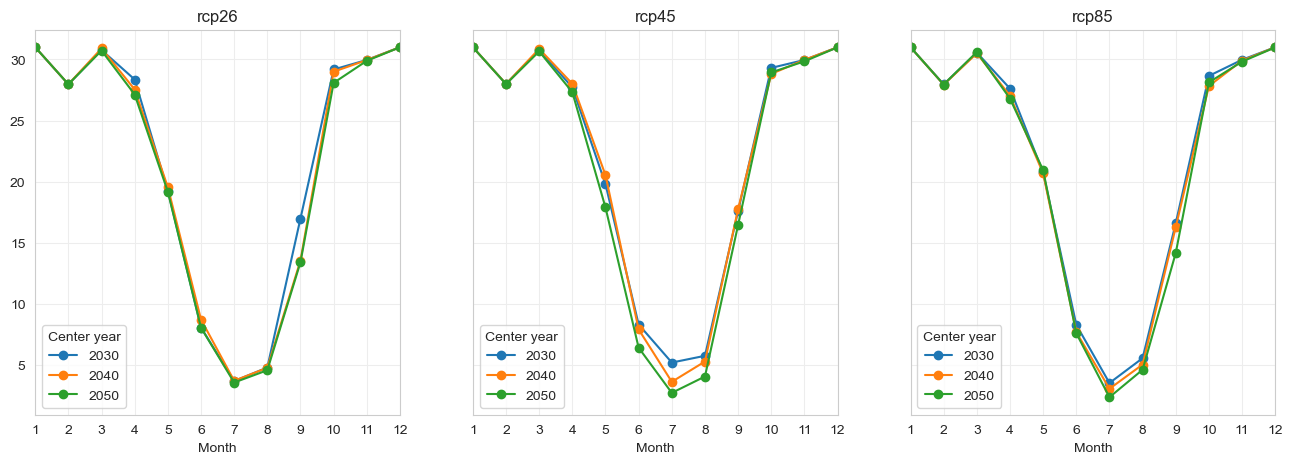

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for i, scen in enumerate(ds_demand_centers["scenario"].values):
    for year in centers:
        da = (
            ds_demand_centers.sel(scenario=scen, country="Switzerland", month=str(year))
            .heating_days
        )
        months = da["month"].dt.month  # month numbers 1-12
        ax[i].plot(months, da.values, marker="o", label=str(year))

    ax[i].set_xlabel("Month")
    ax[i].set_xticks(range(1, 13))
    ax[i].set_xlim(1, 12)
    ax[i].set_title(f"{scen}")
    ax[i].legend(title="Center year")

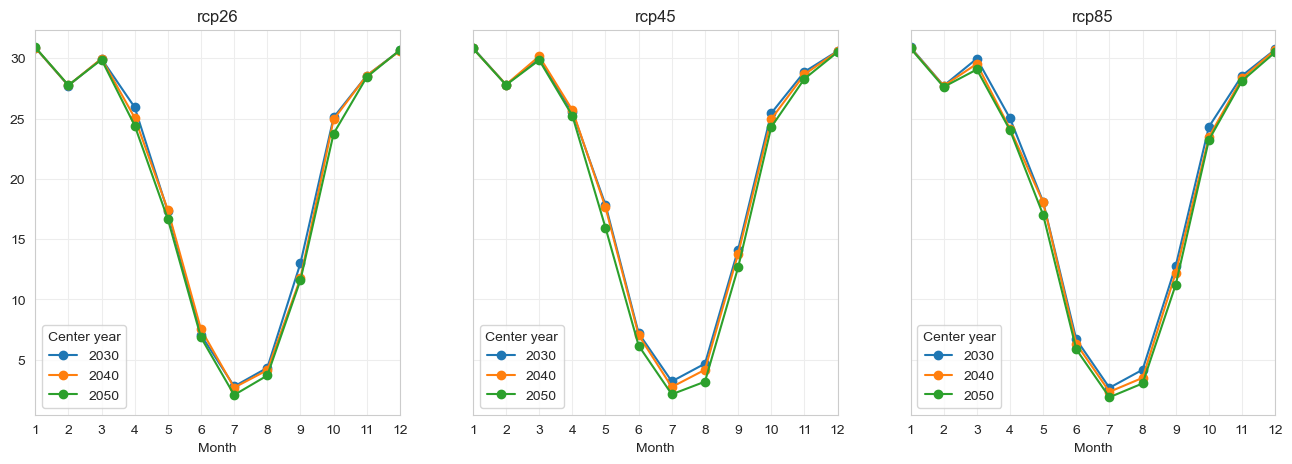

In [32]:
ds_demand_centers_europe = ds_demand_centers.mean("country")

fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for i, scen in enumerate(ds_demand_centers_europe["scenario"].values):
    for year in centers:
        da = (
            ds_demand_centers_europe.sel(scenario=scen, month=str(year))
            .heating_days
        )
        months = da["month"].dt.month  # month numbers 1-12
        ax[i].plot(months, da.values, marker="o", label=str(year))

    ax[i].set_xlabel("Month")
    ax[i].set_xticks(range(1, 13))
    ax[i].set_xlim(1, 12)
    ax[i].set_title(f"{scen}")
    ax[i].legend(title="Center year")
plt.show()

#### Cooling

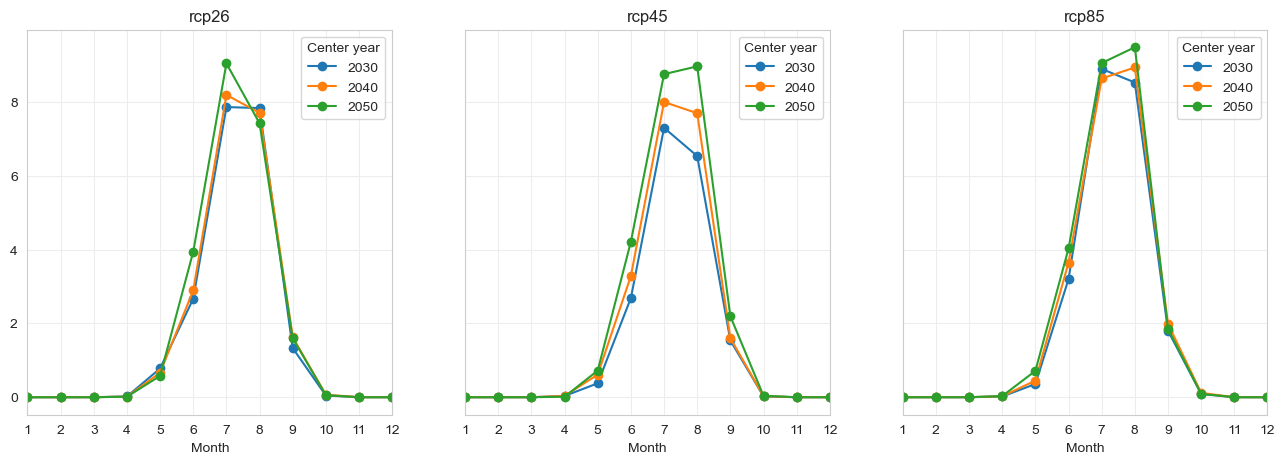

In [33]:
ds_demand_centers_europe = ds_demand_centers.mean("country")

fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for i, scen in enumerate(ds_demand_centers_europe["scenario"].values):
    for year in centers:
        da = (
            ds_demand_centers_europe.sel(scenario=scen, month=str(year))
            .cooling_days
        )
        months = da["month"].dt.month  # month numbers 1-12
        ax[i].plot(months, da.values, marker="o", label=str(year))

    ax[i].set_xlabel("Month")
    ax[i].set_xticks(range(1, 13))
    ax[i].set_xlim(1, 12)
    ax[i].set_title(f"{scen}")
    ax[i].legend(title="Center year")
plt.show()

### Heating and cooling days from national population-weighted temperature data

In [ ]:
ds_demand_temp_weighted = xr.open_dataset(
    path_demand_website_data
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_temperature_weighted.nc"
)

In [ ]:
list_ds_demand = []
centers = [2030, 2040, 2050]
for center in centers:
    start = center - 4
    end = center + 5
    ds_center_mean = (
        ds_demand_temp_weighted.sel(time=slice(str(start), str(end)))
        .groupby("time.month")
        .mean("time")
    )
    months = ds_center_mean["month"].values
    month_ends = (
        pd.to_datetime([f"{center}-{int(m):02d}-01" for m in months])
        .to_period("M")
        .to_timestamp("M")
    )
    ds_center_mean = ds_center_mean.assign_coords(month=month_ends)
    list_ds_demand.append(ds_center_mean)
ds_demand_temp_weighted_centers = xr.concat(list_ds_demand, dim="month")

#### Heating days

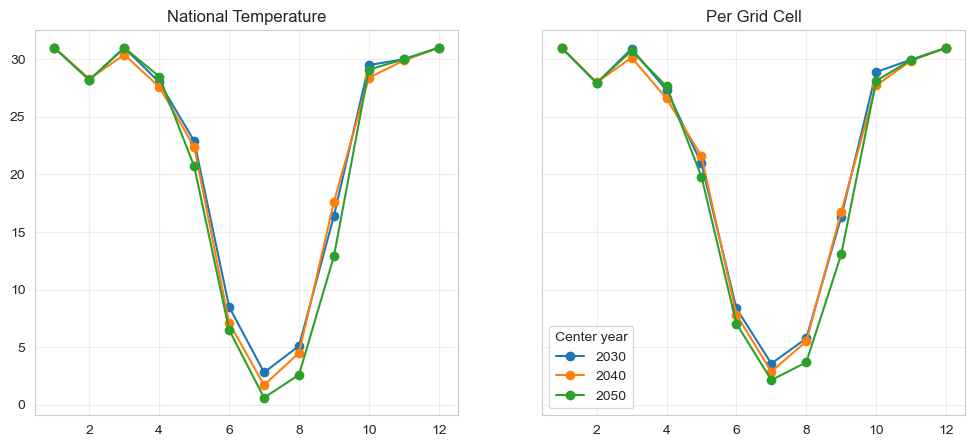

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for year in centers:
    da = ds_demand_temp_weighted_centers.sel(
        country="Switzerland", month=str(year)
    ).heating_days
    months = da["month"].dt.month  # month numbers 1-12
    ax[0].plot(months, da.values, marker="o", label=str(year))

    da = (
        ds_demand_centers.sel(country="Switzerland", month=str(year))
        .isel(band=0)
        .heating_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[1].plot(months, da.values, marker="o", label=str(year))

ax[0].set_title("National Temperature (Switzerland)")
ax[1].set_title("Per Grid Cell (Switzerland)")
plt.legend(title="Center year")
plt.show()

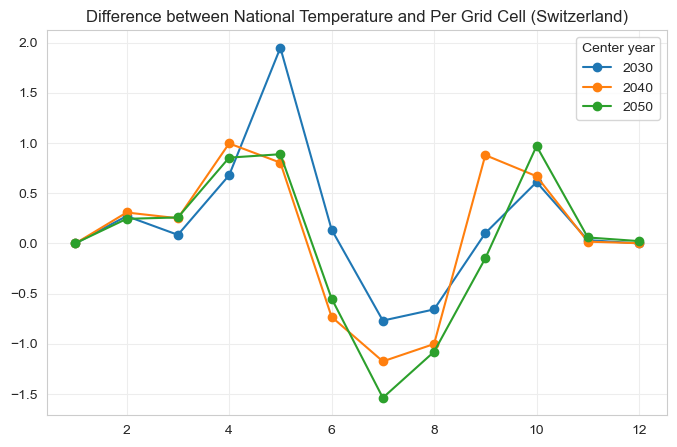

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(
            country="Switzerland", month=str(year)
        ).heating_days
        - ds_demand_centers.sel(country="Switzerland", month=str(year))
        .isel(band=0)
        .heating_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax.plot(months, da.values, marker="o", label=str(year))

ax.set_title("Difference between National Temperature and Per Grid Cell (Switzerland)")
plt.legend(title="Center year")
plt.show()

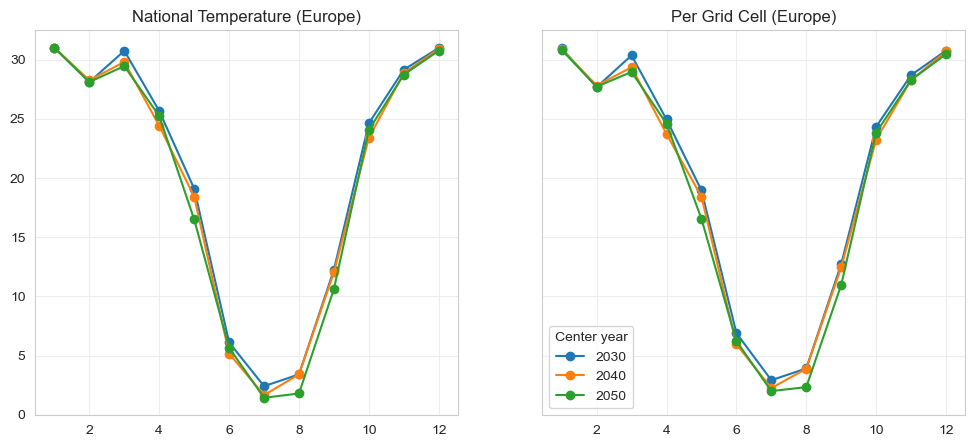

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(month=str(year))
        .mean("country")
        .heating_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[0].plot(months, da.values, marker="o", label=str(year))

    da = (
        ds_demand_centers.sel(month=str(year)).isel(band=0).mean("country").heating_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[1].plot(months, da.values, marker="o", label=str(year))

ax[0].set_title("National Temperature (Europe)")
ax[1].set_title("Per Grid Cell (Europe)")
plt.legend(title="Center year")
plt.show()

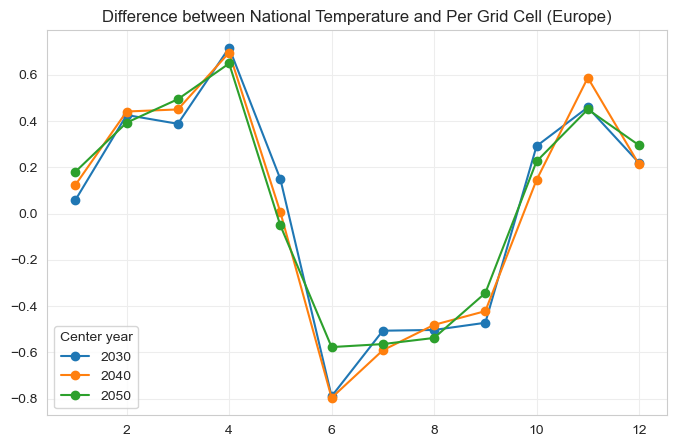

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(
             month=str(year)
        ).mean("country").heating_days
        - ds_demand_centers.sel(month=str(year))
        .isel(band=0)
        .mean("country").heating_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax.plot(months, da.values, marker="o", label=str(year))

ax.set_title("Difference between National Temperature and Per Grid Cell (Europe)")
plt.legend(title="Center year")
plt.show()

#### Cooling days

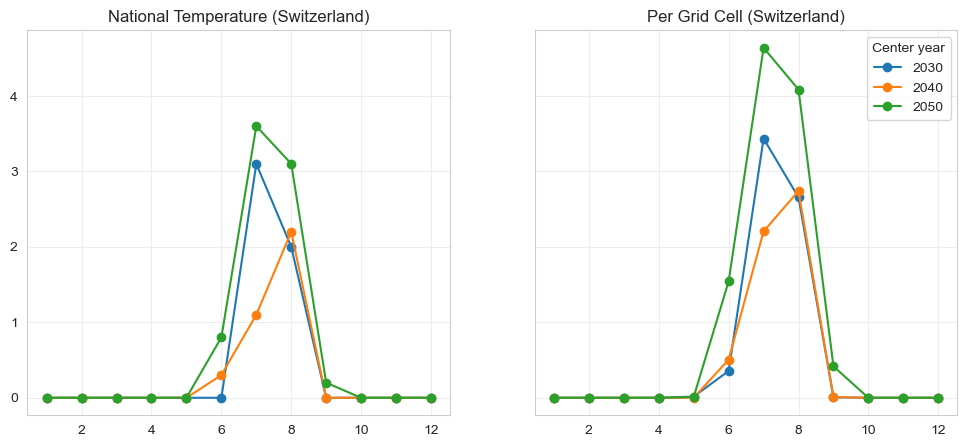

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for year in centers:
    da = ds_demand_temp_weighted_centers.sel(
        country="Switzerland", month=str(year)
    ).cooling_days
    months = da["month"].dt.month  # month numbers 1-12
    ax[0].plot(months, da.values, marker="o", label=str(year))

    da = (
        ds_demand_centers.sel(country="Switzerland", month=str(year))
        .isel(band=0)
        .cooling_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[1].plot(months, da.values, marker="o", label=str(year))

ax[0].set_title("National Temperature (Switzerland)")
ax[1].set_title("Per Grid Cell (Switzerland)")
plt.legend(title="Center year")
plt.show()

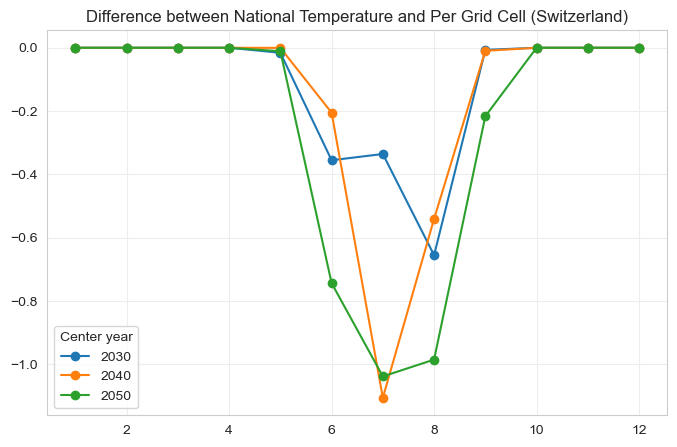

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(
            country="Switzerland", month=str(year)
        ).cooling_days
        - ds_demand_centers.sel(country="Switzerland", month=str(year))
        .isel(band=0)
        .cooling_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax.plot(months, da.values, marker="o", label=str(year))

ax.set_title("Difference between National Temperature and Per Grid Cell (Switzerland)")
plt.legend(title="Center year")
plt.show()

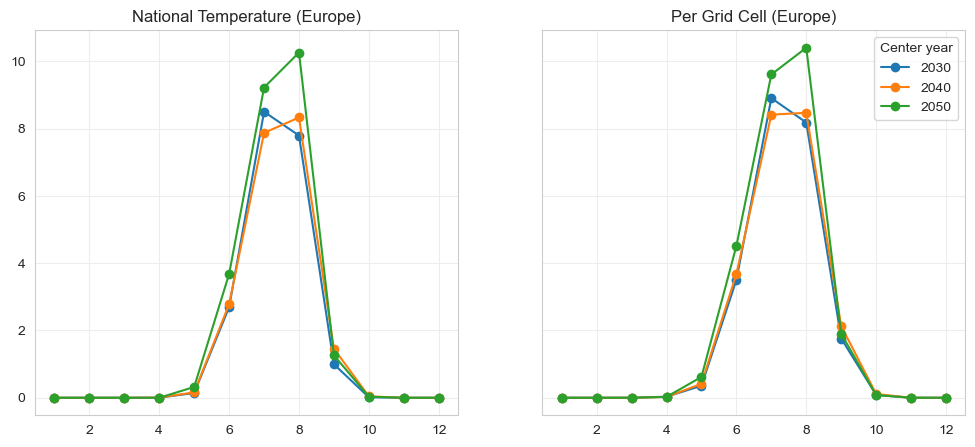

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(month=str(year))
        .mean("country")
        .cooling_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[0].plot(months, da.values, marker="o", label=str(year))

    da = (
        ds_demand_centers.sel(month=str(year)).isel(band=0).mean("country").cooling_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax[1].plot(months, da.values, marker="o", label=str(year))

ax[0].set_title("National Temperature (Europe)")
ax[1].set_title("Per Grid Cell (Europe)")
plt.legend(title="Center year")
plt.show()

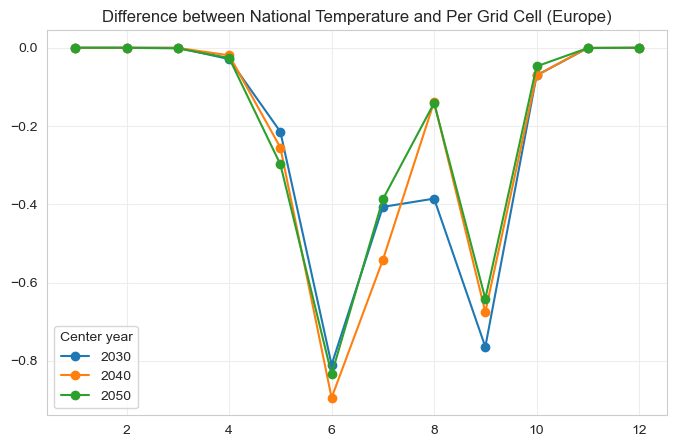

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))

for year in centers:
    da = (
        ds_demand_temp_weighted_centers.sel(
             month=str(year)
        ).mean("country").cooling_days
        - ds_demand_centers.sel(month=str(year))
        .isel(band=0)
        .mean("country").cooling_days
    )
    months = da["month"].dt.month  # month numbers 1-12
    ax.plot(months, da.values, marker="o", label=str(year))

ax.set_title("Difference between National Temperature and Per Grid Cell (Europe)")
plt.legend(title="Center year")
plt.show()

## Temperature anomalies

In [5]:
ds_temp_anomalies = []
for path in path_temperature_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*_decadal_temperature_anomalies.nc"):
    scenario = next((p for p in path.stem.split("_") if p.startswith("rcp")), None)
    ds = xr.open_dataset(path)
    if scenario:
        ds = ds.rename({"tas": f"{scenario}"})
    ds_temp_anomalies.append(ds)

ds_temp_anomalies = xr.merge(ds_temp_anomalies)

ds_temp_anomalies_cantons = []
for path in path_temperature_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*_decadal_temperature_anomalies_cantons.nc"):
    scenario = next((p for p in path.stem.split("_") if p.startswith("rcp")), None)
    ds = xr.open_dataset(path)
    if scenario:
        ds = ds.rename({"tas": f"{scenario}"})
    ds_temp_anomalies_cantons.append(ds)

ds_temp_anomalies_cantons = xr.merge(ds_temp_anomalies_cantons)

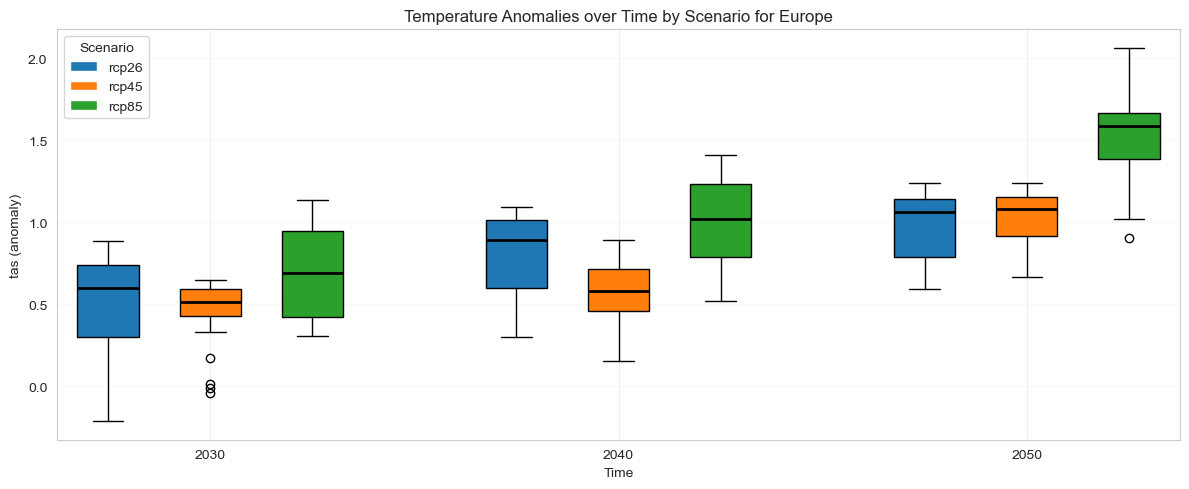

In [6]:
# grouped boxplot: for each time show one box per scenario side-by-side
vars = ["rcp26", "rcp45", "rcp85"]
n = len(vars)
times = ds_temp_anomalies.time
nt = len(times)

group_gap = 1  # gap between groups
group_width = n + group_gap

data = []
positions = []
for i, t in enumerate(times):
    for j, var in enumerate(vars):
        da = ds_temp_anomalies[var].sel(time=t)
        data.append(da.values)
        positions.append(i * group_width + j)

fig, ax = plt.subplots(figsize=(4 * nt, 5))
colors = sns.color_palette("tab10", n)

# set median line to black via medianprops
b = ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True,
               medianprops=dict(color="k", linewidth=2))

# color boxes
for patch, col in zip(b["boxes"], [colors[i % n] for i in range(len(b["boxes"]))]):
    patch.set_facecolor(col)

# ensure medians are black (in case of backend differences)
for median in b["medians"]:
    median.set_color("k")
    median.set_linewidth(2)

# x ticks at group centers
group_centers = [i * group_width + (n - 1) / 2 for i in range(nt)]
ax.set_xticks(group_centers)
ax.set_xticklabels([str(y) for y in times.dt.year.values])
ax.set_xlabel("Time")
ax.set_ylabel("tas (anomaly)")
ax.grid(axis="y", alpha=0.3)

# legend for scenarios
handles = [Patch(facecolor=colors[i], label=vars[i]) for i in range(n)]
ax.legend(handles=handles, title="Scenario", loc="upper left")

plt.title("Temperature Anomalies over Time by Scenario for Europe")
plt.tight_layout()
plt.show()

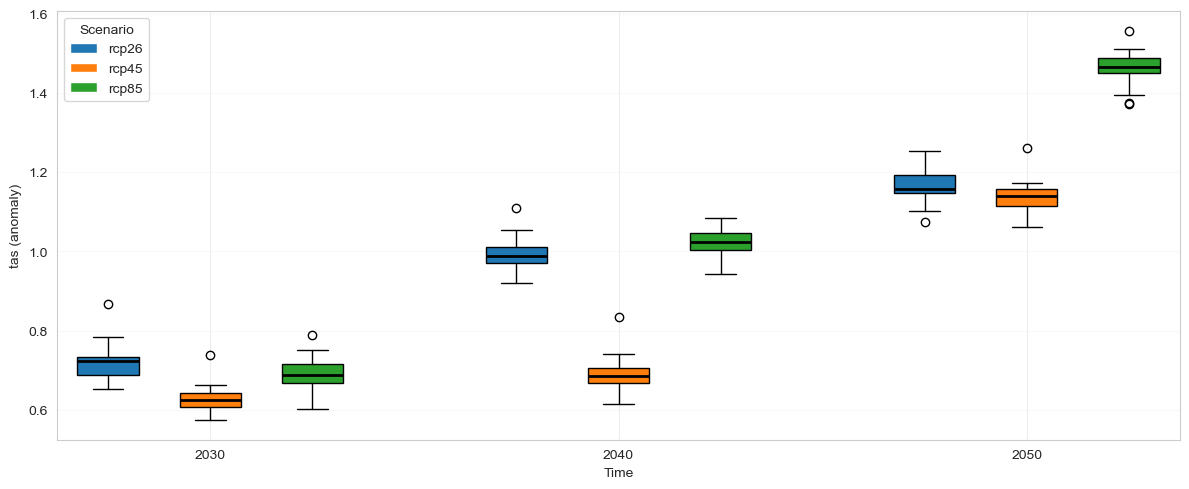

In [7]:
# grouped boxplot: for each time show one box per scenario side-by-side
vars = ["rcp26", "rcp45", "rcp85"]
n = len(vars)
times = ds_temp_anomalies_cantons.time
nt = len(times)

group_gap = 1  # gap between groups
group_width = n + group_gap

data = []
positions = []
for i, t in enumerate(times):
    for j, var in enumerate(vars):
        da = ds_temp_anomalies_cantons[var].sel(time=t)
        data.append(da.values)
        positions.append(i * group_width + j)

fig, ax = plt.subplots(figsize=(4 * nt, 5))
colors = sns.color_palette("tab10", n)

# set median line to black via medianprops
b = ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True,
               medianprops=dict(color="k", linewidth=2))

# color boxes
for patch, col in zip(b["boxes"], [colors[i % n] for i in range(len(b["boxes"]))]):
    patch.set_facecolor(col)

# ensure medians are black (in case of backend differences)
for median in b["medians"]:
    median.set_color("k")
    median.set_linewidth(2)

# x ticks at group centers
group_centers = [i * group_width + (n - 1) / 2 for i in range(nt)]
ax.set_xticks(group_centers)
ax.set_xticklabels([str(y) for y in times.dt.year.values])
ax.set_xlabel("Time")
ax.set_ylabel("tas (anomaly)")
ax.grid(axis="y", alpha=0.3)

# legend for scenarios
handles = [Patch(facecolor=colors[i], label=vars[i]) for i in range(n)]
ax.legend(handles=handles, title="Scenario", loc="upper left")

plt.tight_layout()
plt.show()

# Website data

## Heating and cooling days

In [13]:
import re

ds_demand = []
for path in path_demand_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp[0-9][0-9].nc"):
    scenario_match = re.search(r"rcp\d{2}", path.stem)
    scenario = scenario_match.group(0)
    ds_demand.append(xr.open_dataset(path).expand_dims({"scenario": [scenario]}))

# combine list of datasets into one dataset along the 'scenario' dimension
ds_demand = xr.concat(ds_demand, dim="scenario")
list_ds_demand = []
centers = [2030, 2040, 2050]
for center in centers:
    start = center - 9
    end = center + 10
    ds_center_mean = (
        ds_demand.sel(time=slice(str(start), str(end)))
        .groupby("time.month")
        .mean("time")
    )
    months = ds_center_mean["month"].values
    month_ends = (
        pd.to_datetime([f"{center}-{int(m):02d}-01" for m in months])
        .to_period("M")
        .to_timestamp("M")
    )
    ds_center_mean = ds_center_mean.assign_coords(month=month_ends)
    list_ds_demand.append(ds_center_mean)
ds_demand_centers = xr.concat(list_ds_demand, dim="month")

In [14]:
out_dir = Path("../../data/")
out_dir.mkdir(parents=True, exist_ok=True)

# ds_demand_centers has dims: scenario, country, month
for scen in ds_demand_centers["scenario"].values:
    (out_dir / scen).mkdir(parents=True, exist_ok=True)
    rows_eur = []
    rows_ch = []

    ds_s = ds_demand_centers.sel(scenario=scen)
    ds_eur = ds_s.mean("country")
    ds_ch = ds_s.sel(country="Switzerland")

    for t in ds_eur["month"].values:
        ts = pd.Timestamp(t)
        last = calendar.monthrange(ts.year, ts.month)[1]
        time_str = pd.Timestamp(ts.year, ts.month, last, 23).isoformat()
        h = float(ds_eur.sel(month=str(t))["heating_days"].values)
        c = float(ds_eur.sel(month=str(t))["cooling_days"].values)
        rows_eur.append({
            "time": time_str,
            "area": "europe",
            "heating_degree_days": round(h, 1),
            "cooling_degree_days": round(c, 1),
        })

    for t in ds_ch["month"].values:
        ts = pd.Timestamp(t)
        last = calendar.monthrange(ts.year, ts.month)[1]
        time_str = pd.Timestamp(ts.year, ts.month, last, 23).isoformat()
        h = float(ds_ch.sel(month=str(t))["heating_days"].values)
        c = float(ds_ch.sel(month=str(t))["cooling_days"].values)
        rows_ch.append({
            "time": time_str,
            "area": "switzerland",
            "heating_degree_days": round(h, 1),
            "cooling_degree_days": round(c, 1),
        })

    df_eur = pd.DataFrame(rows_eur)[["time", "area", "heating_degree_days", "cooling_degree_days"]]
    df_ch = pd.DataFrame(rows_ch)[["time", "area", "heating_degree_days", "cooling_degree_days"]]

    eur_fname = out_dir / scen / "europe_hdd_cdd_monthly.csv"
    ch_fname = out_dir / scen / "switzerland_hdd_cdd_monthly.csv"

    df_eur.to_csv(eur_fname, index=False)
    df_ch.to_csv(ch_fname, index=False)

    print(f"Wrote: {eur_fname}")
    print(f"Wrote: {ch_fname}")

Wrote: ../../data/rcp26/europe_hdd_cdd_monthly.csv
Wrote: ../../data/rcp26/switzerland_hdd_cdd_monthly.csv
Wrote: ../../data/rcp45/europe_hdd_cdd_monthly.csv
Wrote: ../../data/rcp45/switzerland_hdd_cdd_monthly.csv
Wrote: ../../data/rcp85/europe_hdd_cdd_monthly.csv
Wrote: ../../data/rcp85/switzerland_hdd_cdd_monthly.csv


## Temperature anomalies

In [10]:
ds_temp_anomalies = []
for path in path_temperature_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*_decadal_temperature_anomalies.nc"):
    scenario = next((p for p in path.stem.split("_") if p.startswith("rcp")), None)
    ds = xr.open_dataset(path)
    if scenario:
        ds = ds.rename({"tas": f"{scenario}"})
    ds_temp_anomalies.append(ds)

ds_temp_anomalies = xr.merge(ds_temp_anomalies)

ds_temp_anomalies_cantons = []
for path in path_temperature_website_data.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*_decadal_temperature_anomalies_cantons.nc"):
    scenario = next((p for p in path.stem.split("_") if p.startswith("rcp")), None)
    ds = xr.open_dataset(path)
    if scenario:
        ds = ds.rename({"tas": f"{scenario}"})
    ds_temp_anomalies_cantons.append(ds)

ds_temp_anomalies_cantons = xr.merge(ds_temp_anomalies_cantons)

In [11]:
out_dir = Path("../../data/")
out_dir.mkdir(parents=True, exist_ok=True)

# scenarios are stored as data variables in ds_temp_anomalies
scenarios = [str(v) for v in ds_temp_anomalies.data_vars]

for scen in scenarios:
    (out_dir / scen).mkdir(parents=True, exist_ok=True)
    # COUNTRY-LEVEL (Europe per country)
    da_country = ds_temp_anomalies[scen]
    times = da_country['time'].values

    rows_country = []
    for t in times:
        ts = pd.Timestamp(t)
        time_str = pd.Timestamp(ts.year, 12, 31, 23).isoformat()
        vals = da_country.sel(time=t).values
        names = da_country["country"].values
        for name, val in zip(names, vals):
            rows_country.append({
                'time': time_str,
                'area': 'europe',
                'location': str(name),
                'temperature': float(pd.NA) if pd.isna(val) else round(float(val), 1),
                'unit': 'c',
            })

    df_country = pd.DataFrame(rows_country)[['time', 'area', 'location', 'temperature', 'unit']]
    europe_country_fname = out_dir / scen / "europe_temperature_per_country_yearly.csv"
    df_country.to_csv(europe_country_fname, index=False)
    print(f"Wrote: {europe_country_fname}")

    # EUROPE AGGREGATE (mean across countries)
    europe_mean_da = da_country.mean(dim="country")
    rows_europe = []
    for t in times:
        ts = pd.Timestamp(t)
        time_str = pd.Timestamp(ts.year, 12, 31, 23).isoformat()
        v = europe_mean_da.sel(time=t).values
        rows_europe.append({
            'time': time_str,
            'area': 'europe',
            'temperature': round(float(v), 1) if not pd.isna(v) else float('nan'),
            'unit': 'c',
        })
    df_europe = pd.DataFrame(rows_europe)[['time', 'area', 'temperature', 'unit']]
    europe_fname = out_dir / scen / "europe_temperature_yearly.csv"
    df_europe.to_csv(europe_fname, index=False)
    print(f"Wrote: {europe_fname}")

    # SWISS-LEVEL
    sw_val_da = ds_temp_anomalies[scen].sel(country='Switzerland')
    rows_sw = []
    for t in times:
        ts = pd.Timestamp(t)
        time_str = pd.Timestamp(ts.year, 12, 31, 23).isoformat()
        v = sw_val_da.sel(time=t).values
        rows_sw.append({'time': time_str, 'area': 'switzerland', 'temperature': round(float(v), 1), 'unit': 'c'})
    df_sw = pd.DataFrame(rows_sw)[['time', 'area', 'temperature', 'unit']]

    sw_fname = out_dir / scen / "switzerland_temperature_yearly.csv"
    df_sw.to_csv(sw_fname, index=False)
    print(f"Wrote: {sw_fname}")

    # CANTON-LEVEL (Switzerland per canton)
    da_canton = ds_temp_anomalies_cantons[scen]
    times_c = da_canton['time'].values

    rows_canton = []
    for t in times_c:
        ts = pd.Timestamp(t)
        time_str = pd.Timestamp(ts.year, 12, 31, 23).isoformat()
        vals = da_canton.sel(time=t).values
        names = da_canton["canton"].values
        for name, val in zip(names, vals):
            rows_canton.append({
                'time': time_str,
                'area': 'switzerland',
                'location': str(name),
                'temperature': float(pd.NA) if pd.isna(val) else round(float(val), 1),
                'unit': 'c',
            })

    df_canton = pd.DataFrame(rows_canton)[['time', 'area', 'location', 'temperature', 'unit']]
    canton_fname = out_dir / scen / "switzerland_temperature_per_canton_yearly.csv"
    df_canton.to_csv(canton_fname, index=False)
    print(f"Wrote: {canton_fname}")

Wrote: ../../data/rcp45/europe_temperature_per_country_yearly.csv
Wrote: ../../data/rcp45/europe_temperature_yearly.csv
Wrote: ../../data/rcp45/switzerland_temperature_yearly.csv
Wrote: ../../data/rcp45/switzerland_temperature_per_canton_yearly.csv
Wrote: ../../data/rcp85/europe_temperature_per_country_yearly.csv
Wrote: ../../data/rcp85/europe_temperature_yearly.csv
Wrote: ../../data/rcp85/switzerland_temperature_yearly.csv
Wrote: ../../data/rcp85/switzerland_temperature_per_canton_yearly.csv
Wrote: ../../data/rcp26/europe_temperature_per_country_yearly.csv
Wrote: ../../data/rcp26/europe_temperature_yearly.csv
Wrote: ../../data/rcp26/switzerland_temperature_yearly.csv
Wrote: ../../data/rcp26/switzerland_temperature_per_canton_yearly.csv
